# Setup

In [1]:
import sys

from Part_2.course22p2.miniai.datasets import show_image, inplace, DataLoaders

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

import pickle, gzip, math, os, time, shutil, torch, matplotlib as mpl, numpy as np, matplotlib.pyplot as plt
import sys, gc, traceback
import fastcore.all as fc
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter, itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager

import torchvision.transforms.functional as TF, torch.nn.functional as F
from torch import tensor, nn, optim
from torch.utils.data import DataLoader, default_collate
from torch.nn import init
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset, load_dataset_builder

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from fastcore.test import test_close

torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)

import logging

logging.disable(logging.WARNING)

set_seed(42)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
xl,yl = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

@inplace
def transformi(b): b[xl] = [TF.to_tensor(o) for o in b[xl]]

bs = 1024
tds = dsd.with_transform(transformi)

dls = DataLoaders.from_dd(tds, bs, num_workers=4)
dt = dls.train
xb,yb = next(iter(dt))
xb.shape,yb[:10]

(torch.Size([1024, 1, 28, 28]), tensor([5, 7, 4, 7, 3, 8, 9, 5, 3, 1]))

In [3]:
def get_model():
    return nn.Sequential(conv(1 ,8), conv(8 ,16), conv(16,32), conv(32,64),
                         conv(64,10, act=False), nn.Flatten()).to(def_device)

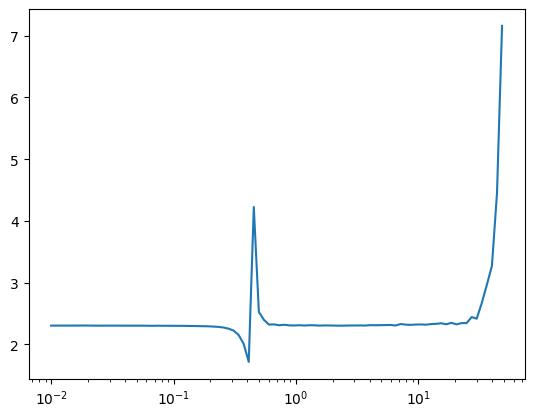

In [4]:
MomentumLearner(get_model(), dls, F.cross_entropy, cbs=[DeviceCB()]).lr_find(gamma=1.1, start_lr=1e-2)

that is the lr finder plot

In [5]:
metrics = MetricsCB(accuracy=MulticlassAccuracy())
astats = ActivationStats(fc.risinstance(nn.ReLU))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
learn = MomentumLearner(get_model(), dls, F.cross_entropy, lr=0.2, cbs=cbs)

accuracy,loss,epoch,train
0.302,1.883,0,train
0.665,0.869,0,eval


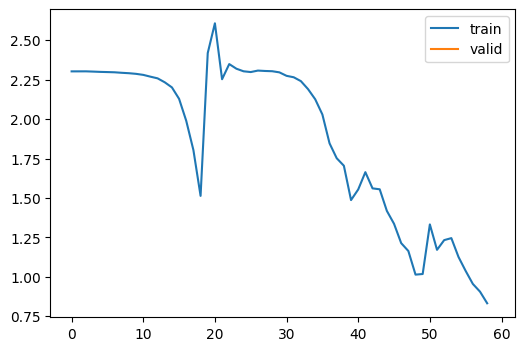

In [6]:
learn.fit(1)

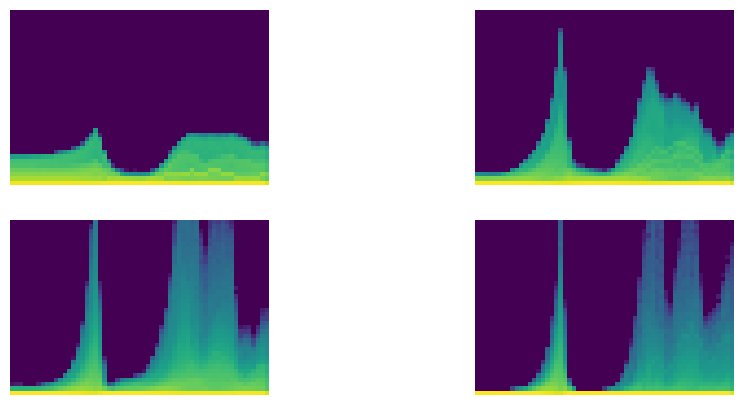

In [7]:
astats.color_dim()

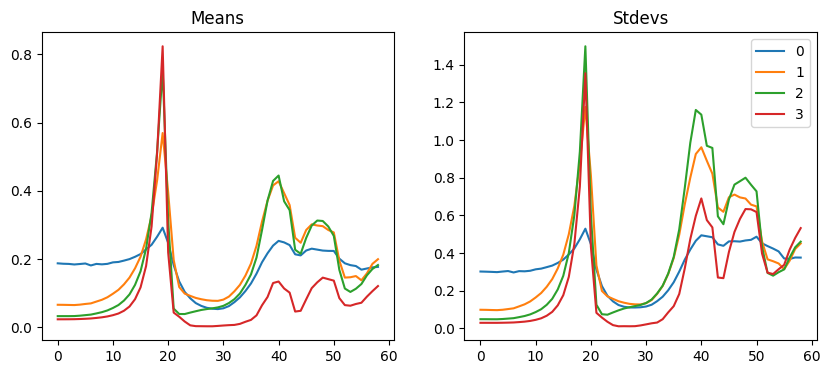

In [8]:
astats.plot_stats()

 Make some Memory Cleaning Functions

In [9]:
def clean_ipython_hist():
    # Code in this function mainly copied from IPython source
    if not 'get_ipython' in globals(): return
    ip = get_ipython()
    user_ns = ip.user_ns
    ip.displayhook.flush()
    pc = ip.displayhook.prompt_count + 1
    for n in range(1, pc): user_ns.pop('_i' + repr(n), None)
    user_ns.update(dict(_i='', _ii='', _iii=''))
    hm = ip.history_manager
    hm.input_hist_parsed[:] = [''] * pc
    hm.input_hist_raw[:] = [''] * pc
    hm._i = hm._ii = hm._iii = hm._i00 = ''

def clean_tb():
    # h/t Piotr Czapla
    if hasattr(sys, 'last_traceback'):
        traceback.clear_frames(sys.last_traceback)
        delattr(sys, 'last_traceback')
    if hasattr(sys, 'last_type'): delattr(sys, 'last_type')
    if hasattr(sys, 'last_value'): delattr(sys, 'last_value')

def clean_mem():
    clean_tb()
    clean_ipython_hist()
    gc.collect()
    torch.cuda.empty_cache()

# Glorot/Xavier init

In [10]:
# over the 50 iteration , the result explodes
x = torch.randn(200, 100)
for i in range(50): x = x @ torch.randn(100,100)
x[0:5,0:5]

tensor([[nan, nan, nan, nan, nan],
        [nan, nan, nan, nan, nan],
        [nan, nan, nan, nan, nan],
        [nan, nan, nan, nan, nan],
        [nan, nan, nan, nan, nan]])

In [11]:
# over the 50 iteration with harsh scaling down , the result vanishes
x = torch.randn(200, 100)
for i in range(50): x = x @ (torch.randn(100,100) * 0.01)
x[0:5,0:5]

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

So we have to scale our weight matrices exactly right so that the standard deviation of our activations stays at 1. We can compute the exact value to use mathematically, as illustrated by Xavier Glorot and Yoshua Bengio in ["Understanding the Difficulty of Training Deep Feedforward Neural Networks"](http://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf). The right scale for a given layer is $1/\sqrt{n_{in}}$, where $n_{in}$ represents the number of inputs.

In [12]:
x = torch.randn(200, 100)
for i in range(50): x = x @ (torch.randn(100,100) * 0.1) # N(inp) = 100
x[0:5,0:5]

tensor([[ 1.33, -1.54,  0.54,  0.13,  3.51],
        [ 0.20,  0.95,  0.61, -0.02,  1.73],
        [-0.69,  1.72,  0.36, -0.64, -2.40],
        [ 0.03,  0.73,  0.40, -1.24, -0.64],
        [ 0.33, -0.33,  0.03, -0.32,  0.62]])

looks better

# Background

# Variance and STDs

In [13]:
t = torch.tensor([1.,2.,4.,18])
m = t.mean()

In [14]:
# Variance
(t-m).pow(2).mean()

tensor(47.19)

In [15]:
# Std
(t-m).pow(2).mean().sqrt()

tensor(6.87)

In [16]:
# mean absolute deviation
(t-m).abs().mean()

tensor(5.88)

In [17]:
# we can make the variance as this
(t-m).pow(2).mean(), (t*t).mean() - (m*m)

(tensor(47.19), tensor(47.19))

$$\text{Var}(X) = \text{E}\left[(X - \text{E}[X])^2\right]$$$$= \text{E}\left[X^2 - 2X\text{E}[X] + \text{E}[X]^2\right]$$$$= \text{E}[X^2] - 2\text{E}[X]\text{E}[X] + \text{E}[X]^2$$$$= \text{E}[X^2] - 2\text{E}[X]^2 + \text{E}[X]^2$$$$= \text{E}[X^2] - \text{E}[X]^2$$

## Covariance

$$\operatorname{cov}(X,Y) = \operatorname{E}{\big[(X - \operatorname{E}[X])(Y - \operatorname{E}[Y])\big]}$$

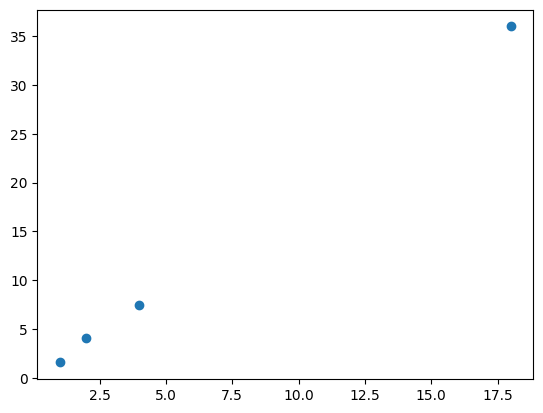

In [26]:
# `u` is twice `t`, plus a bit of randomness
u = t*2
u *= torch.randn_like(t)/10+0.95

plt.scatter(t, u);

In [27]:
t,u

(tensor([ 1.,  2.,  4., 18.]), tensor([ 1.57,  4.10,  7.47, 35.98]))

In [28]:
# apply the formula
prod = (t-t.mean())*(u-u.mean()) ; prod

tensor([ 56.23,  34.76,  10.82, 278.46])

In [29]:
cov = prod.mean() ; cov

tensor(95.07)

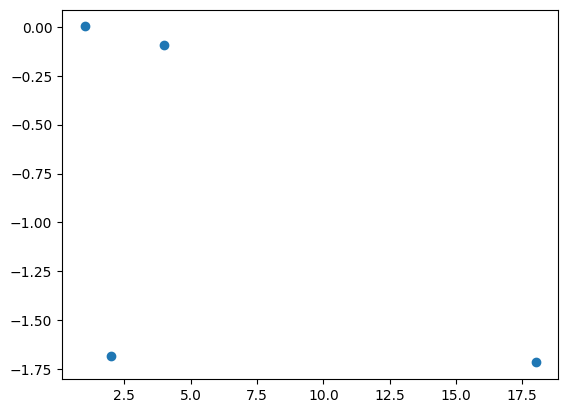

In [30]:
# lets see a more scattered relation
v = torch.randn_like(t)
plt.scatter(t, v);

In [32]:
cov = ((t-t.mean())*(v-v.mean())).mean() ; cov

tensor(-3.20)

another simpler equation
$$\operatorname{E}\left[X Y\right] - \operatorname{E}\left[X\right] \operatorname{E}\left[Y\right]$$


In [33]:
cov = (t*v).mean() - t.mean()*v.mean(); cov

tensor(-3.20)

## Pearson corr (r)
- a more scaled covariance (bet [-1,1]) , just divide by the product of the stds

$$\rho_{X,Y}= \frac{\operatorname{cov}(X,Y)}{\sigma_X \sigma_Y}$$


In [34]:
cov / (t.std() * v.std())

tensor(-0.42)

# Xavier init derivation

When we do `y = a @ x`, the coefficients of `y` are defined by

$$y_{i} = a_{i,0} x_{0} + a_{i,1} x_{1} + \cdots + a_{i,n-1} x_{n-1} = \sum_{k=0}^{n-1} a_{i,k} x_{k}$$

or in pure python code:
```
y[i] = sum([c*d for c,d in zip(a[i], x)])
```

or in numpy/pytorch code:
```
y[i] = (a[i]*x).sum()
```

At the very beginning, our `x` vector has a mean of roughly 0. and a standard deviation of roughly 1. (since we picked it that way).

In [36]:
x = torch.randn(100)
x.mean(), x.std()

(tensor(0.05), tensor(1.02))

If we go back to `y = a @ x` and assume that we chose weights for `a` that also have a mean of 0, we can compute the standard deviation of `y` quite easily. Since it's random, and we may fall on bad numbers, we repeat the operation 100 times.

In [37]:
mean,sqr = 0.,0.
for i in range(100):
    x = torch.randn(100)
    a = torch.randn(512, 100)
    y = a @ x
    mean += y.mean().item()
    sqr  += y.pow(2).mean().item()
mean/100,sqr/100

(0.026637999787926674, 100.02469367980957)

Now that looks very close to the dimension of our matrix 100. And that's no coincidence! When you compute y, you sum 100 product of one element of a by one element of x. So what's the mean and the standard deviation of such a product? We can show mathematically that as long as the elements in `a` and the elements in `x` are independent, the mean is 0 and the std is 1. This can also be seen experimentally:

In [38]:
mean,sqr = 0.,0.
for i in range(10000):
    x = torch.randn(1)
    a = torch.randn(1)
    y = a*x
    mean += y.item()
    sqr  += y.pow(2).item()
mean/10000,sqr/10000

(-0.0030411464155225077, 0.9700034639227357)

One Line Conclusion:
If you divide your weights by sqrt(n) where n = number of inputs, your activations stay std=1 through ALL layers.

    WITHOUT dividing:
    ─────────────────────────────────────────
    layer 1: std = 10
    layer 2: std = 100
    layer 3: std = 1000
    ...
    layer 10: std = 10,000,000,000 → EXPLODES ✗
    WITH dividing by sqrt(100):
    ─────────────────────────────────────────
    layer 1: std = 1
    layer 2: std = 1
    layer 3: std = 1
    ...
    layer 10: std = 1 → STABLE ✓

# Kaiming/He init

In [40]:
from math import sqrt

In [41]:
# data
x = torch.randn(200, 100)
y = torch.randn(200)
# weights
w1 = torch.randn(100,50) / sqrt(100)
b1 = torch.zeros(50)
w2 = torch.randn(50,1) / sqrt(50)
b2 = torch.zeros(1)

In [42]:
def lin(x, w, b): return x @ w + b

In [43]:
l1 = lin(x, w1, b1)
l1.mean(),l1.std()

(tensor(0.02), tensor(1.01))

we can see result is great

In [44]:
def relu(x): return x.clamp_min(0.)

In [45]:
l2 = relu(l1)
l2.mean(),l2.std()

(tensor(0.41), tensor(0.60))

relu messes the whole thing. So, In ["Delving Deep into Rectifiers: Surpassing Human-Level Performance"](https://arxiv.org/abs/1502.01852) Kaiming He et al. show that we should use the following scale instead: $\sqrt{2 / n_{in}}$, where $n_{in}$ is the number of inputs of our model.

In [47]:
# proving the relu doesnt work with the previous formula
x = torch.randn(200, 100)
for i in range(50): x = relu(x @ (torch.randn(100,100) * 0.1))
x[0:5,0:5]

tensor([[    0.00,     0.00,     0.00,     0.00,     0.00],
        [    0.00,     0.00,     0.00,     0.00,     0.00],
        [    0.00,     0.00,     0.00,     0.00,     0.00],
        [    0.00,     0.00,     0.00,     0.00,     0.00],
        [    0.00,     0.00,     0.00,     0.00,     0.00]])

In [48]:
# now with the new formula
x = torch.randn(200, 100)
for i in range(50): x = relu(x @ (torch.randn(100,100) * sqrt(2/100)))
x[0:5,0:5]

tensor([[0.00, 0.29, 0.00, 2.26, 0.00],
        [0.00, 0.34, 0.00, 2.24, 0.00],
        [0.00, 0.33, 0.00, 1.84, 0.00],
        [0.00, 0.32, 0.00, 1.60, 0.00],
        [0.00, 0.28, 0.00, 1.77, 0.00]])

looks better

# Applying and init fn

In [49]:
model = get_model()
model.apply(lambda m: print(type(m).__name__));

Conv2d
ReLU
Sequential
Conv2d
ReLU
Sequential
Conv2d
ReLU
Sequential
Conv2d
ReLU
Sequential
Conv2d
Flatten
Sequential


In [50]:
def init_weights(m):
    if isinstance(m, (nn.Conv1d,nn.Conv2d,nn.Conv3d)): init.kaiming_normal_(m.weight)

`kaiming_normal_` -> the formula that have ...  $\sqrt{2 / n_{in}}$ ... , applied in place

In [51]:
model.apply(init_weights);

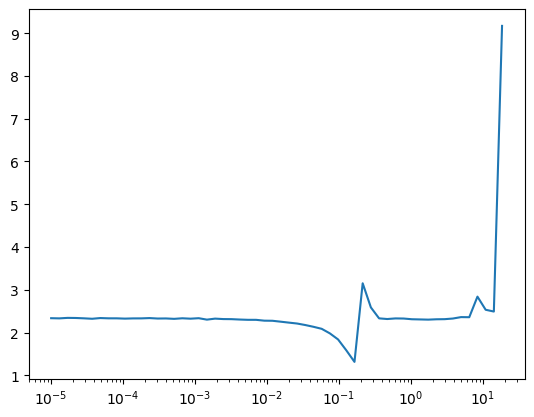

In [52]:
MomentumLearner(model, dls, F.cross_entropy, cbs=[DeviceCB()]).lr_find()

In [53]:
set_seed(42)
learn = MomentumLearner(get_model().apply(init_weights), dls, F.cross_entropy, lr=0.2, cbs=cbs)

accuracy,loss,epoch,train
0.607,1.173,0,train
0.778,0.577,0,eval
0.825,0.471,1,train
0.830,0.459,1,eval
0.851,0.401,2,train
0.849,0.408,2,eval


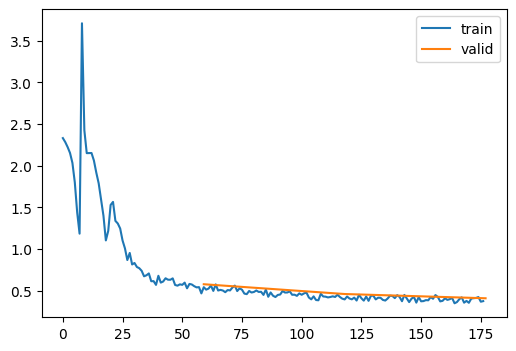

In [54]:
learn.fit(3)

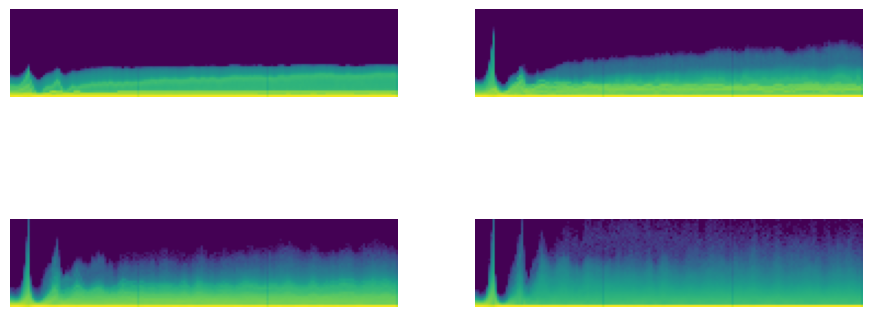

In [55]:
astats.color_dim()

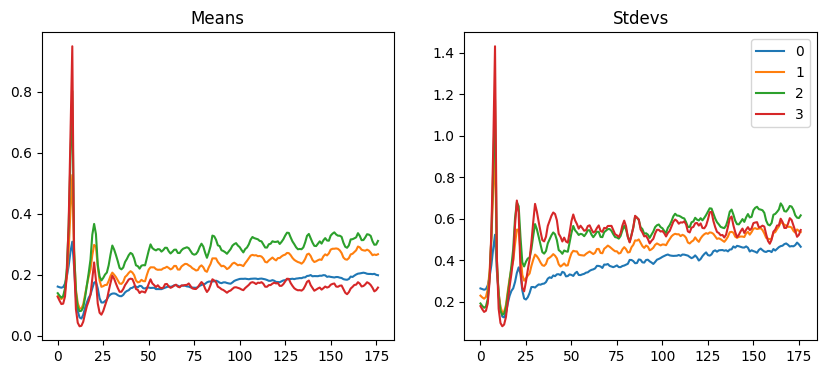

In [57]:
astats.plot_stats()

# Input normalization

In [58]:
xmean,xstd = xb.mean(),xb.std()
xmean,xstd

(tensor(0.29), tensor(0.35))

In [80]:
# A Callback before the batch so that we can apply any thing we want to the batch
class BatchTransformCB(Callback):
    def __init__(self, tfm, on_train=True, on_val=True): fc.store_attr()

    def before_batch(self, learn):
        if (self.on_train and learn.training) or (self.on_val and not learn.training):
            learn.batch = self.tfm(learn.batch)

Normalization :$$  \frac{(x - mean)} {std}$$

In [86]:
# this is called normalization
x  = torch.tensor([1.,4.,6.,18.])
y = (x-(x.mean()))/x.std()
x.mean(),x.std() , y.mean(),y.std()

(tensor(7.25), tensor(7.46), tensor(0.), tensor(1.))

In [87]:
def _norm(b): return (b[0]-xmean)/xstd,b[1]
norm = BatchTransformCB(_norm)

accuracy,loss,epoch,train
0.545,1.404,0,train
0.762,0.628,0,eval
0.811,0.513,1,train
0.819,0.493,1,eval
0.841,0.434,2,train
0.846,0.429,2,eval


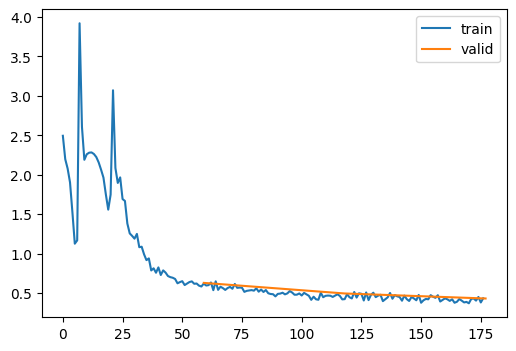

In [90]:
set_seed(42)
learn = MomentumLearner(get_model().apply(init_weights), dls, F.cross_entropy, lr=0.2, cbs=cbs+[norm])
learn.fit(3)

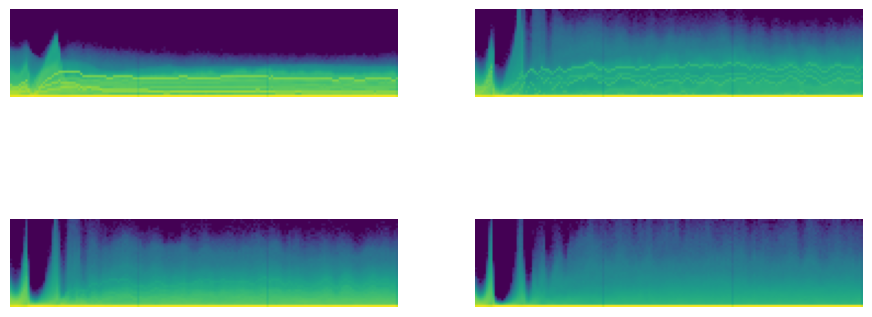

In [91]:
astats.color_dim()

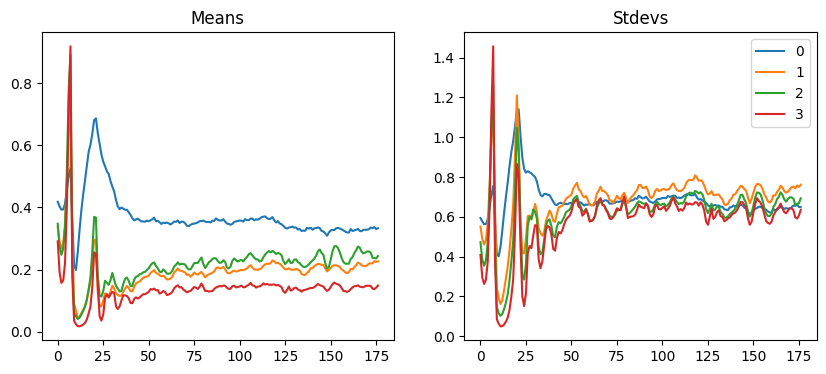

In [92]:
astats.plot_stats()

In [93]:
# this is another way to make the same thing using a transform instead of callback (make same thing)
@inplace
def transformi(b): b[xl] = [(TF.to_tensor(o)-xmean)/xstd for o in b[xl]]
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=4)
xb,yb = next(iter(dls.train))

In [94]:
xb.mean(),xb.std()

(tensor(0.01), tensor(1.00))

# General Relu

In [96]:
class GeneralRelu(nn.Module):
    def __init__(self,leak=None,sub=None,maxv=None):
        super().__init__()
        self.leak,self.sub,self.maxv = leak,sub,maxv
    def forward(self,x):
        x = F.leaky_relu(x,self.leak) if self.leak is not None else F.relu(x)
        if self.sub is not None: x -= self.sub
        if self.maxv is not None: x.clamp_max_(self.maxv)
        return x

    GeneralRelu full picture:
    ─────────────────────────────────────────
    normal ReLU:     max(0, x)
                     negatives → 0
                     positives → kept

    leak=0.1:        negatives → x*0.1 (not fully killed)
                     positives → kept

    sub=0.4:         everything → x - 0.4
                     shifts activations down
                     helps keep mean near 0 ✓

    maxv=6:          everything above 6 → 6
                     prevents explosions ✓

In [97]:
# plot it
def plot_func(f, start=-5., end=5., steps=100):
    x = torch.linspace(start, end, steps)
    plt.plot(x, f(x))
    plt.grid(True, which='both', ls='--')
    plt.axhline(y=0, color='k', linewidth=0.7)
    plt.axvline(x=0, color='k', linewidth=0.7)

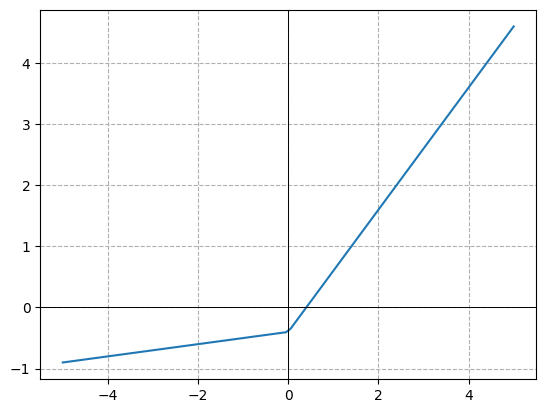

In [102]:
plot_func(GeneralRelu(leak=0.1, sub=0.4))

In [103]:
def conv(ni, nf, ks=3, stride=2, act=nn.ReLU):
    res = nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2)
    if act: res = nn.Sequential(res, act())
    return res

In [104]:
def get_model(act=nn.ReLU, nfs=None):
    if nfs is None: nfs = [1,8,16,32,64]
    layers = [conv(nfs[i], nfs[i+1], act=act) for i in range(len(nfs)-1)]
    return nn.Sequential(*layers, conv(nfs[-1],10, act=None), nn.Flatten()).to(def_device)

In [105]:
def init_weights(m, leaky=0.):
    if isinstance(m, (nn.Conv1d,nn.Conv2d,nn.Conv3d)): init.kaiming_normal_(m.weight, a=leaky)

at `kaiming_normal_`

    # a=0   (plain ReLU)
    std = sqrt(2 / 1 * N_inp)

    # a=0.1 (leaky ReLU)
    std = sqrt(2 / 1.01 * N_inp)

In [106]:
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
astats = ActivationStats(fc.risinstance(GeneralRelu))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
iw = partial(init_weights, leaky=0.1)

In [107]:
model = get_model(act_gr).apply(iw)

accuracy,loss,epoch,train
0.774,0.626,0,train
0.846,0.420,0,eval
0.868,0.362,1,train
0.860,0.375,1,eval
0.880,0.325,2,train
0.867,0.367,2,eval


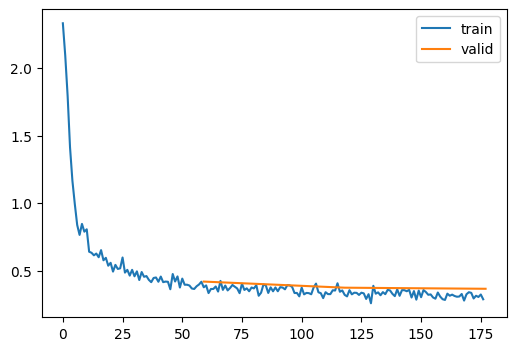

In [108]:
set_seed(42)
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(3)

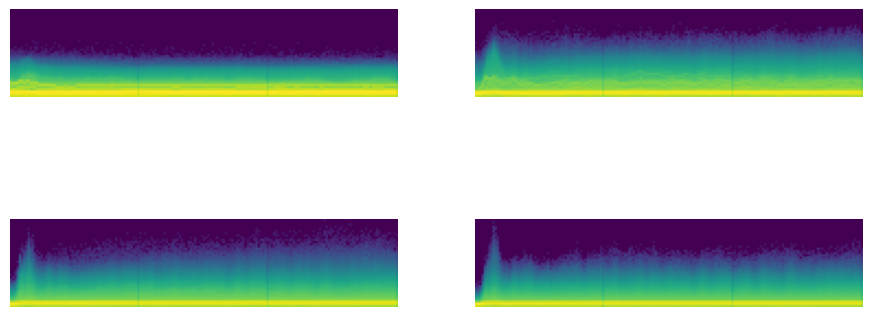

In [109]:
astats.color_dim()

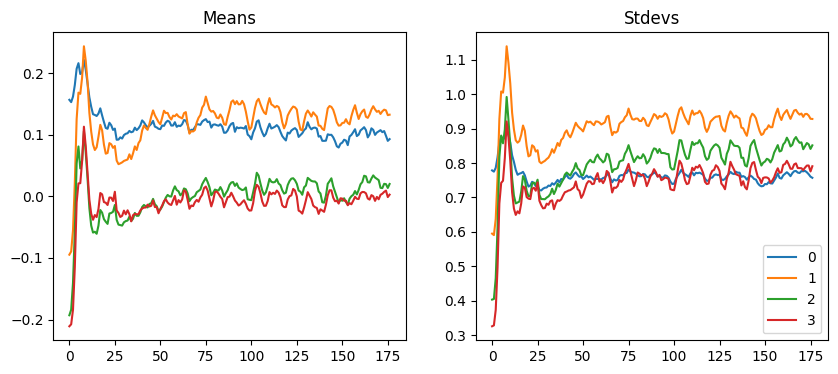

In [110]:
astats.plot_stats()

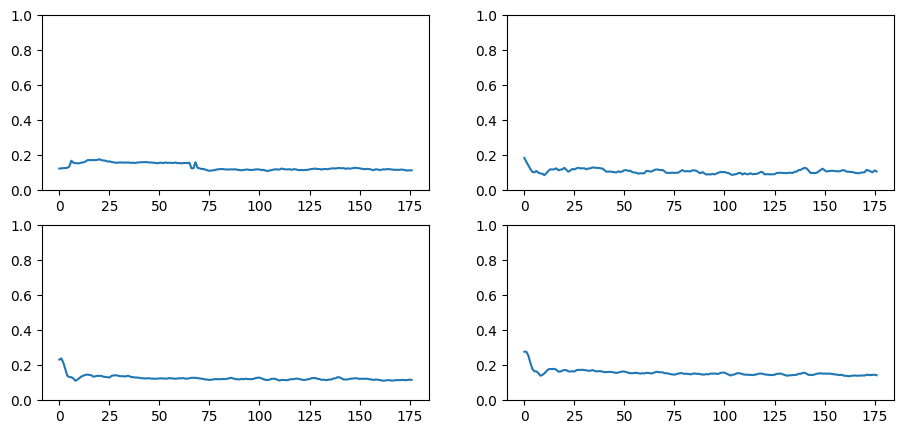

In [111]:
astats.dead_chart()

# LSUV

In [131]:
def _lsuv_stats(hook, mod, inp, outp):
    acts = to_cpu(outp)
    hook.mean = acts.mean()
    hook.std = acts.std()

def lsuv_init(model, layer_out, layer_in, xb):
    h = Hook(layer_out, _lsuv_stats)
    with torch.no_grad():
        while model(xb) is not None and (abs(h.std-1)>1e-3 or abs(h.mean)>1e-3):
            # print(f'before MEAN: {h.mean:.3f} | STD: {h.std:.3f} ')
            layer_in.bias -= h.mean
            layer_in.weight.data /= h.std
            # print(f'after  MEAN: {h.mean:.3f} | STD: {h.std:3f} ')
    h.remove()

here:
- Layer_in : conv
- layer_out : the ReLU after the conv

In [132]:
model = get_model(act_gr) # act_gr is the leaky relu we made
relus = [o for o in model.modules() if isinstance(o, GeneralRelu)]
convs = [o for o in model.modules() if isinstance(o, nn.Conv2d)]

In [133]:
for ms in zip(relus,convs): print(ms)

(GeneralRelu(), Conv2d(1, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)))
(GeneralRelu(), Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)))
(GeneralRelu(), Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)))
(GeneralRelu(), Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)))


In [134]:
for ms in zip(relus,convs): lsuv_init(model, *ms, xb.to(def_device))

before MEAN: -0.172 | STD: 0.344 
after  MEAN: -0.172 | STD: 0.343758 
before MEAN: 0.295 | STD: 0.989 
after  MEAN: 0.295 | STD: 0.989279 
before MEAN: 0.127 | STD: 0.905 
after  MEAN: 0.127 | STD: 0.905164 
before MEAN: 0.120 | STD: 0.958 
after  MEAN: 0.120 | STD: 0.958470 
before MEAN: 0.089 | STD: 0.960 
after  MEAN: 0.089 | STD: 0.960273 
before MEAN: 0.074 | STD: 0.973 
after  MEAN: 0.074 | STD: 0.972676 
before MEAN: 0.059 | STD: 0.978 
after  MEAN: 0.059 | STD: 0.977549 
before MEAN: 0.048 | STD: 0.983 
after  MEAN: 0.048 | STD: 0.982905 
before MEAN: 0.039 | STD: 0.986 
after  MEAN: 0.039 | STD: 0.986093 
before MEAN: 0.032 | STD: 0.989 
after  MEAN: 0.032 | STD: 0.988905 
before MEAN: 0.026 | STD: 0.991 
after  MEAN: 0.026 | STD: 0.990978 
before MEAN: 0.022 | STD: 0.993 
after  MEAN: 0.022 | STD: 0.992703 
before MEAN: 0.018 | STD: 0.994 
after  MEAN: 0.018 | STD: 0.994053 
before MEAN: 0.015 | STD: 0.995 
after  MEAN: 0.015 | STD: 0.995157 
before MEAN: 0.012 | STD: 0.996 

accuracy,loss,epoch,train
0.759,0.693,0,train
0.845,0.433,0,eval
0.859,0.385,1,train
0.860,0.387,1,eval
0.876,0.335,2,train
0.863,0.370,2,eval


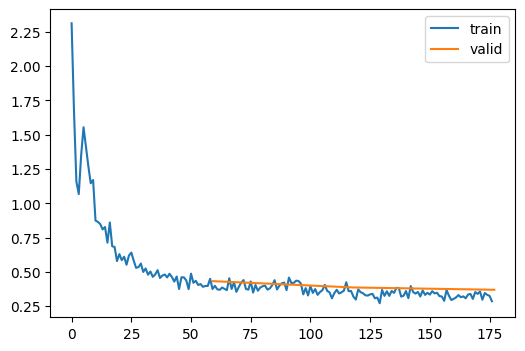

In [135]:
set_seed(42)
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(3)

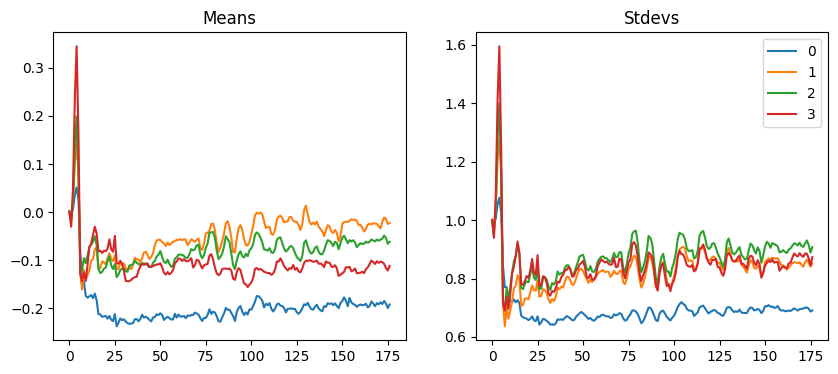

In [136]:
astats.plot_stats()

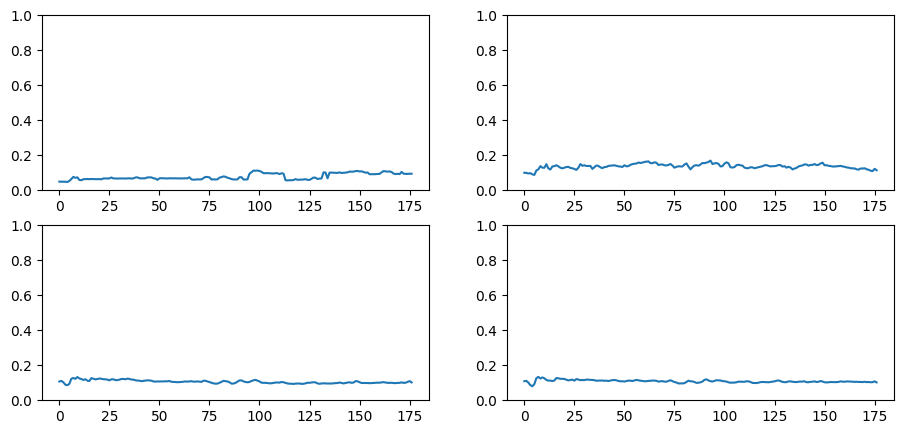

In [138]:
astats.dead_chart()

# LayerNorm

In [144]:
class LayerNorm(nn.Module):
    def __init__(self, dummy, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.mult = nn.Parameter(tensor(1.))
        self.add  = nn.Parameter(tensor(0.))

    def forward(self, x):
        m = x.mean((1,2,3), keepdim=True # out_shape if bs=16 -> (16, 1, 1, 1)
        v = x.var ((1,2,3), keepdim=True)
        x = (x-m) / ((v+self.eps).sqrt())
        return x*self.mult + self.add

In [145]:
def conv(ni, nf, ks=3, stride=2, act=nn.ReLU, norm=None, bias=None):
    if bias is None: bias = not isinstance(norm, (nn.BatchNorm1d,nn.BatchNorm2d,nn.BatchNorm3d))
    layers = [nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2, bias=bias)]
    if norm: layers.append(norm(nf))
    if act: layers.append(act())
    return nn.Sequential(*layers)

In [146]:
def get_model(act=nn.ReLU, nfs=None, norm=None):
    if nfs is None: nfs = [1,8,16,32,64]
    layers = [conv(nfs[i], nfs[i+1], act=act, norm=norm) for i in range(len(nfs)-1)]
    return nn.Sequential(*layers, conv(nfs[-1],10, act=None, norm=False, bias=True),
                         nn.Flatten()).to(def_device)

accuracy,loss,epoch,train
0.781,0.606,0,train
0.846,0.422,0,eval
0.864,0.370,1,train
0.859,0.376,1,eval
0.882,0.321,2,train
0.866,0.361,2,eval


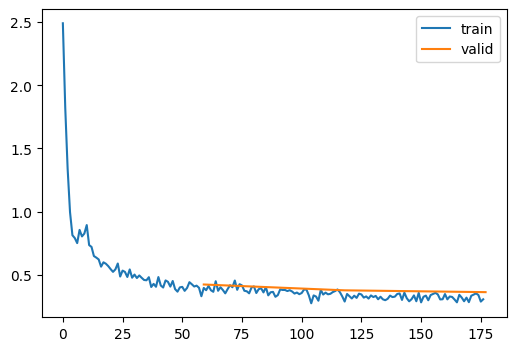

In [147]:
set_seed(42)
model = get_model(act_gr, norm=LayerNorm).apply(iw)
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(3)

# BatchNorm

In [148]:
class BatchNorm(nn.Module):
    def __init__(self, nf, mom=0.1, eps=1e-5):
        super().__init__()
        # NB: pytorch bn mom is opposite of what you'd expect
        self.mom,self.eps = mom,eps
        self.mults = nn.Parameter(torch.ones (nf,1,1))
        self.adds  = nn.Parameter(torch.zeros(nf,1,1))
        self.register_buffer('vars',  torch.ones(1,nf,1,1))
        self.register_buffer('means', torch.zeros(1,nf,1,1))

    def update_stats(self, x):
        m = x.mean((0,2,3), keepdim=True) # out_shape is n_channels(filters)=32 -> (1, 32, 1, 1)
        v = x.var ((0,2,3), keepdim=True)
        self.means.lerp_(m, self.mom)
        self.vars.lerp_ (v, self.mom)
        return m,v

    def forward(self, x):
        if self.training:
            with torch.no_grad(): m,v = self.update_stats(x)
        else: m,v = self.means,self.vars
        x = (x-m) / (v+self.eps).sqrt()
        return x*self.mults + self.adds

`register_buffer`:
- we make instance record the attr at self
- have this information recorded inside the model when we make like torch.save(model) , but it is not a learnable

accuracy,loss,epoch,train
0.799,0.551,0,train
0.842,0.482,0,eval
0.874,0.342,1,train
0.863,0.377,1,eval
0.885,0.306,2,train
0.868,0.360,2,eval


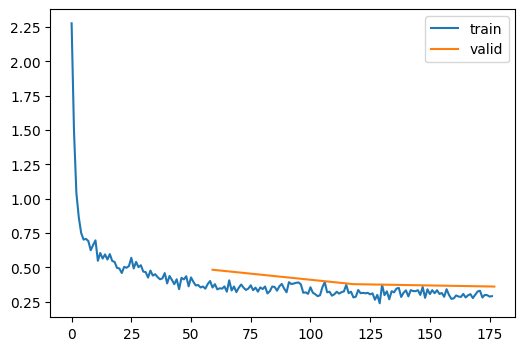

In [149]:
model = get_model(act_gr, norm=BatchNorm).apply(iw)
set_seed(42)
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.4, cbs=cbs) # you can see the we can use a bigger LR now when using the BatchNorm
learn.fit(3)

# What Diff norms does
And it is worth noting that we in each technique of Normalization , We are using a smaller set of techniques so we could combine some of this techniques from different normalization techniques and possibly make even a new type of normalization.

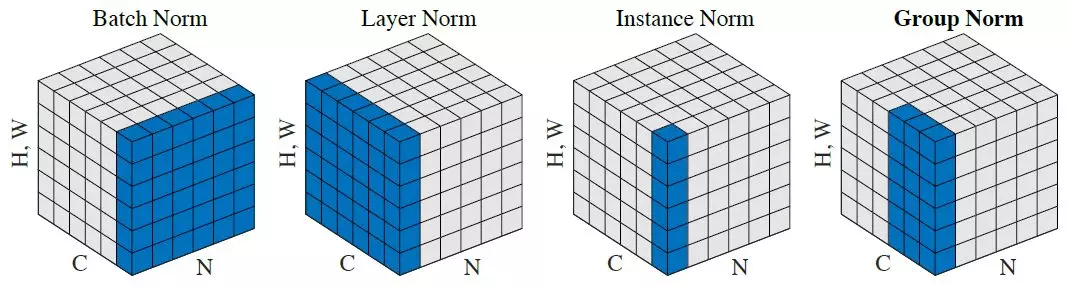

# 90 ACC (smaller BS)

In [151]:
dls = DataLoaders.from_dd(tds, 256, num_workers=4)

accuracy,loss,epoch,train
0.836,0.451,0,train
0.866,0.366,0,eval
0.882,0.318,1,train
0.861,0.371,1,eval
0.896,0.280,2,train
0.889,0.310,2,eval


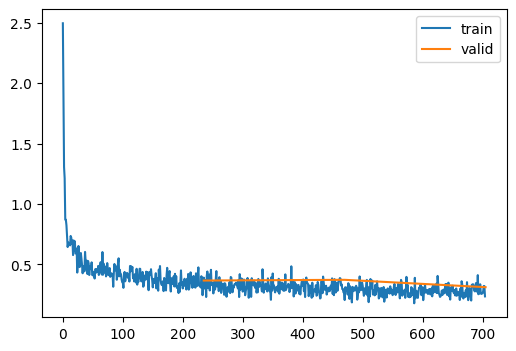

In [152]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(3)

accuracy,loss,epoch,train
0.918,0.224,0,train
0.895,0.285,0,eval
0.923,0.211,1,train
0.900,0.278,1,eval


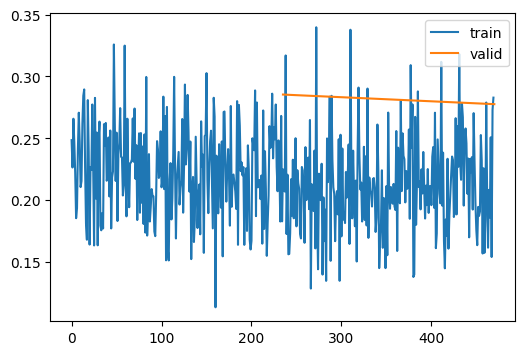

In [153]:
# fine tune it with smaller LR
learn = MomentumLearner(model, dls, F.cross_entropy, lr=0.05, cbs=cbs)
learn.fit(2)